# Measuring Wealth Inequality in Denmark



# Problem 1.1:

## Problem 1.1.1
For the following exercise we utilize the provided code

In [5]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation="Code", **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-801501
1,P1,006,1829,2024,-437821
2,P1,006,3039,2024,-1097902
3,P1,006,4049,2024,-1128378
4,P1,006,5059,2024,-968947


In [16]:
settings2 = dict(DEFINITION='D20', ALDER='*', PRISENHED='006', Tid='2024')
wealth = download('FORMUE15', FORMUE='*', **settings2)
wealth.head()

,FORMUE,DEFINITION,ALDER,PRISENHED,TID,value
0,0000M10,D20,1802,006,2024,35488
1,0000M10,D20,1829,006,2024,2199
2,0000M10,D20,3039,006,2024,9488
3,0000M10,D20,4049,006,2024,8438
4,0000M10,D20,5059,006,2024,7737


> 1.1.1 Explanation: 

For the sake of simplicity we will leave out a detailed explanation for why we wish to import the `numpy`, `pandas` and `matplotlib.pyplot` packages - these are already explained in detail in the DataCamp courses. Instead, we pay attention to the package `reguests` and `io`. The reason as to why we wish to keep the `requests` package is due to the simplicity that it provide when we wish to retrieve data from an URL. In combination with the `request` package, the `io` package, specifically `BytesIO`, provides an easy way for python to read raw binary data retrieved from the API, by creating a "pseudo"-like fil that python can convert to readable data which we can treat with pandas.  

We observe that the original `def download()` uses two parameters `table` and `**selectors` to retrieve the data and both needs an explanation seperatly.

First, the `table` parameter is a placeholder parameter, used to define what table python should retrieve from Statbank. We can see from Line 9 that we define `url` as a f-string of Statbanks general API and a variable `{table}`. That is, whenever we use the `download()` function, we define in the first argument the exact table name we wish python to retrieve data from, e.g. FORMUE15 or FORMUE16, which python the manually inserts into the `{table}` part of the API. This corresponds to redirecting python to a table specific API without having to create a new API on Statbank and change the URL all the time.

Secondly the `**selectors` is also a placeholder parameter, used to insert a dictionary with $n$ inputs which we define in the second argument `download()`. This is particularly useful when we use `settings` as a dictionary that stores all necessary table values from the corresponding table. 

From these two observations, we then looked specifically at `settings` and `wealth` to define how python should retrieve the data from the Statbank. Starting with `settings` we defined 5 parameters Formue, Definition, Alder, Prisenhed og Tid to match that of the exercise. We have simplified the code a little, so instead of including 'Formue' in `wealth` function, we put 'Formue' into `**settings`. 

## Exercise 1.1.2

In [3]:
percentiles18 = percentiles[percentiles['ALDER'] == '1802']
wealth18 = wealth[wealth['ALDER'] == '1802']

> Explanation 1.1.2

Because "age" is defined in our data retrieval as a code-specific age grouping, we need to search up on [API Statbank](https://api.statbank.dk/console#data) the corresponding codes for all adults with an age greater than or equal to 18 for both FORMUE15 and FORMUE16. We observed that the age groups codes is equivalent for both dataset which simplifies our approach a lot. 

We observed that the corresponding code for all adults with an age greater than or equal to 18 was '1802'. Since we in the `download()` definition, line 10, defined `valuePresentation='Code'` we may utilize this code to filter the age groups by their corresponding group codes. A different approach would've been needed if we instead utilized `valuePresentation='Value'`. 

Because our data retriavel follows the same formatting as Statbank, the filtering method is simple. We first utilize a boolean defined by `percentiles['Alder'] == '1802'` or `wealth['Alder'] == '1802'` to filter statements into either "True" or "False" depending on whether the statement match our required age-group code. Taking the outer operators `percentiles[]` or `wealth[]` converts these true and false statements back into values which is stored respectively as `percentiles18` and `wealth18` for later uses. 

# Exercise 1.2 Plot the Age Profiles

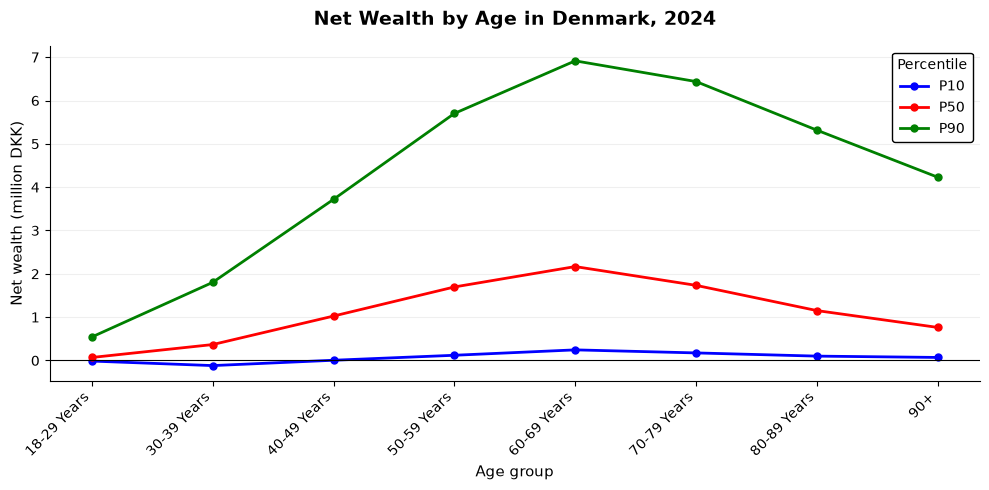

In [18]:
# Define the Age Labels as A Dictionary
age_labels = {
    '1802': 'All adults',
    '1829': '18-29 Years',
    '3039': '30-39 Years',
    '4049': '40-49 Years',
    '5059': '50-59 Years',
    '6069': '60-69 Years',
    '7079': '70-79 Years',
    '8089': '80-89 Years',
    '9099': '90+'
}

# Restructure the percentile data, excluding the all-adult group
age_profiles = percentiles[
    percentiles['ALDER'] != '1802'
].pivot_table(
    index='ALDER',
    columns='PERCENTIL',
    values='value'
)

# Apply age labels and remove the column index name
age_profiles = age_profiles.rename(index=age_labels)
age_profiles.index.name = 'Age'
age_profiles.columns.name = None

# Plot the three selected percentiles
(age_profiles[['P10', 'P50', 'P90']] / 1e6).plot(
    figsize=(10, 5),
    marker='o',
    linewidth=2,
    markersize=5,
    color=["blue","red","green"]
)

# Plotting the Figure
## Title Definition
plt.title('Net Wealth by Age in Denmark, 2024',
          fontsize=14, fontweight='bold', pad=15)

## Label the x-axis
plt.xlabel('Age group', fontsize=11)
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=45, ha='right')

## Define the y-label
plt.ylabel('Net wealth (million DKK)', fontsize=11)

## Allow for grid
plt.grid(axis='y', alpha=0.2)

## Remove top and right Current Axes
plt.gca().spines[['top', 'right']].set_visible(False)

## Define colors and visbility for Legend Box
plt.legend(
    title='Percentile',
    frameon=True,
    edgecolor='black',
    facecolor='white',
    framealpha=1
)

plt.tight_layout()
plt.show()

> Explanation:

To not stray far away from the assignment, we have utilized the disctionary-approach to define the code-specific.

## Exercise 1.2.2

In [22]:
age_profiles['Upper gap'] = age_profiles['P90'] - age_profiles['P50']
age_profiles['Lower gap'] = age_profiles['P50'] - age_profiles['P10']

# Display Age as a column without changing age_profiles
age_profiles[['P10', 'P50', 'P90', 'Upper gap', 'Lower gap']].reset_index().style.hide(axis='index').format(precision=0, thousands=',')


Age,P10,P50,P90,Upper gap,Lower gap
18-29 Years,"-14,254","68,806","541,878","473,072","83,060"
30-39 Years,"-118,420","366,935","1,802,110","1,435,175","485,355"
40-49 Years,"4,660","1,024,656","3,718,363","2,693,707","1,019,996"
50-59 Years,"119,753","1,696,187","5,700,964","4,004,777","1,576,434"
60-69 Years,"244,332","2,166,898","6,915,373","4,748,475","1,922,566"
70-79 Years,"174,039","1,733,634","6,437,553","4,703,919","1,559,595"
80-89 Years,"100,122","1,151,164","5,315,410","4,164,246","1,051,042"
90+,"69,644","762,475","4,229,814","3,467,339","692,831"


In [34]:
amount = int(age_profiles['Upper gap'].max())
ageamount = age_profiles['Upper gap'].idxmax()

print(f'The largest spread is {amount:,} DKK which is found at the age group {ageamount}')

The largest spread is 4,748,475 DKK which is found at the age group 60-69 Years


## Exercise 1.2.3

In [ ]:
for age in age_profiles
    